# Chapter 6: Validating Deployed Models

**Aventum Round 1 prep · STRATEGY.md §5.4** · Time needed: about 75 minutes

The JD lists **offline replay, A/B testing, shadow deployment and simulation**. This chapter does each one with numbers.

### Syllabus
| No. | Topic | Interview use |
|---|---|---|
| 6.1 | The validation ladder | "How would you ship a model?" (say it unprompted) |
| 6.2 | Offline replay / off-policy evaluation: replay, IPS, SNIPS, DM, DR | "Can you evaluate a new policy before deploying it?" |
| 6.3 | Shadow deployment: agreement and Cohen's kappa | "Your model looks great offline but underwriters ignore it" |
| 6.4 | A/B tests: sample size, z-test, guardrails, peeking, randomisation unit | "Design the experiment" |
| 6.5 | Canary releases and rollback rules | "How do you limit the blast radius?" |

## 0. Setup

In [1]:
import numpy as np                  # linear algebra
import pandas as pd                 # data processing
import matplotlib.pyplot as plt     # plots
from scipy import stats
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

np.random.seed(42)
print("Ready")

Ready


---
## 6.1 The Validation Ladder (learn the order)

| Rung | What happens | Risk to the business | What you learn |
|---|---|---|---|
| **1. Offline replay** | Run the new model or policy over **historical** logs | None | Would it have decided differently? Estimated value (with OPE) |
| **2. Shadow** | Model runs on **live** traffic; outputs logged, **not acted on** | None | Real latency, errors, data issues, agreement with humans |
| **3. Canary** | Model acts on a small % (say 5%), with automatic rollback | Small | Does it break anything in production? |
| **4. A/B test** | Randomise units between old and new; pre-registered metric | Controlled | The **causal** effect on the business metric |
| **5. Full rollout + monitoring** | Everyone, with drift and performance monitoring | Managed | Long-run behaviour, delayed labels (Notebook 08) |
| *(alongside)* **Simulation** | Test policy changes in the Digital Twin (Notebook 07) | None | "What if" before touching real customers |

> **Say this unprompted** when asked how you'd ship a model: "offline replay, then shadow, then a canary or A/B, then full rollout with monitoring". It maps your production background straight onto their validation accountability.

---
## 6.2 Offline Replay and Off-Policy Evaluation (OPE)

### Theory
We have **logs from the old policy** $\pi_0$: (context $x$, action $a$, reward $r$, propensity $p = \pi_0(a \mid x)$). We want the value of a **new** policy $\pi_e$, *without deploying it*.

**Problem:** the logs only show rewards for actions $\pi_0$ chose. If $\pi_e$ picks a different action, we never saw what would have happened. This is the causal missing-data problem again (Chapter 4).

### Estimators
| Estimator | Formula | Bias / variance |
|---|---|---|
| **Replay** (Li et al.) | Keep rows where $a = \pi_e(x)$ and average their $r$ | Unbiased **only if** $\pi_0$ was uniform random; throws away data |
| **IPS** | $\hat V = \frac1n \sum_i \frac{\pi_e(a_i \mid x_i)}{p_i}\, r_i$ | Unbiased; **high variance** |
| **SNIPS** | $\hat V = \frac{\sum_i w_i r_i}{\sum_i w_i}$, with $w_i = \pi_e(a_i \mid x_i)/p_i$ | Small bias, much lower variance |
| **Direct method (DM)** | Fit a reward model $\hat r(x,a)$; $\hat V = \frac1n \sum_i \hat r(x_i, \pi_e(x_i))$ | Low variance; biased if $\hat r$ is wrong |
| **Doubly robust (DR)** | $\hat V = \frac1n \sum_i \big[\hat r(x_i, \pi_e(x_i)) + w_i (r_i - \hat r(x_i, a_i))\big]$ | Unbiased if **either** the propensities or $\hat r$ are right |

DR here is the same idea as AIPW in Chapter 4.

### Solved Example 6.1 (IPS and SNIPS by hand)
**Q.** Four logged decisions. The new policy $\pi_e$ always chooses *call* for Marine and *revised terms* for Cyber.

| Row | Context | Logged action | Propensity $p$ | Reward $r$ | $\pi_e$ picks | $w = \mathbb 1[a = \pi_e(x)]/p$ |
|---|---|---|---|---|---|---|
| 1 | Marine | call | 0.5 | 1 | call | 1/0.5 = 2 |
| 2 | Marine | email | 0.5 | 0 | call | 0 |
| 3 | Cyber | revised terms | 0.25 | 1 | revised terms | 1/0.25 = 4 |
| 4 | Cyber | call | 0.5 | 1 | revised terms | 0 |

**Solution.**
IPS = (2·1 + 0 + 4·1 + 0) / 4 = 6 / 4 = **1.5**
SNIPS = (2·1 + 4·1) / (2 + 0 + 4 + 0) = 6 / 6 = **1.0**

**Ans.** IPS says the policy's success rate is **1.5**, which is impossible for a probability! That is IPS's variance in action: with few rows, weights like 4 blow up. SNIPS normalises the weights and stays in range.

In [2]:
w = np.array([2, 0, 4, 0]); r = np.array([1, 0, 1, 1])
print("IPS   =", (w * r).mean())
print("SNIPS =", (w * r).sum() / w.sum())

IPS   = 1.5
SNIPS = 1.0


#### Program 6.1: OPE on simulated logs (we know the true value)

In [3]:
contexts = ["Property", "Marine", "Cyber"]
arms = ["call broker", "email reminder", "revised terms"]
true_rate = np.array([[0.10, 0.15, 0.08],
                      [0.20, 0.10, 0.12],
                      [0.05, 0.06, 0.18]])
# OLD logging policy: mostly emails (cheap), some exploration
pi0 = np.array([[0.25, 0.60, 0.15],
                [0.25, 0.60, 0.15],
                [0.25, 0.60, 0.15]])
# NEW policy to evaluate: the best arm per context (deterministic)
pi_e = true_rate.argmax(axis=1)
V_true_new = np.mean([true_rate[c, pi_e[c]] for c in range(3)])
V_true_old = np.mean([(pi0[c] * true_rate[c]).sum() for c in range(3)])
print(f"true value OLD policy: {V_true_old:.4f} | true value NEW policy: {V_true_new:.4f}")

def make_logs(n, seed):
    r = np.random.default_rng(seed)
    c = r.integers(0, 3, n)
    a = np.array([r.choice(3, p=pi0[ci]) for ci in c])
    rew = (r.random(n) < true_rate[c, a]).astype(int)
    return pd.DataFrame(dict(c=c, a=a, p=pi0[c, a], r=rew))

logs = make_logs(5000, seed=0)
logs.head()

true value OLD policy: 0.1102 | true value NEW policy: 0.1767


,c,a,p,r
0,2,1,0.60,0
1,1,0,0.25,0
2,1,2,0.15,0
3,0,1,0.60,0
4,0,1,0.60,0


In [4]:
def ope(logs):
    match = (logs.a.values == pi_e[logs.c.values]).astype(float)
    w = match / logs.p.values
    replay = logs.r.values[match == 1].mean()
    ips = np.mean(w * logs.r.values)
    snips = np.sum(w * logs.r.values) / np.sum(w)
    # direct method: reward model r_hat(c, a) = average logged reward in that (context, action) cell
    cell = logs.groupby(["c", "a"])["r"].mean()
    r_table = np.zeros((3, 3))
    for (ci, ai), v in cell.items():
        r_table[ci, ai] = v
    rh_new = r_table[logs.c.values, pi_e[logs.c.values]]    # model's guess for the NEW action
    rh_log = r_table[logs.c.values, logs.a.values]          # model's guess for the LOGGED action
    dm = rh_new.mean()
    dr = np.mean(rh_new + w * (logs.r.values - rh_log))
    return dict(replay=replay, IPS=ips, SNIPS=snips, DM=dm, DR=dr)

one = ope(logs)
print({k: round(v, 4) for k, v in one.items()}, "| truth:", round(V_true_new, 4))

{'replay': np.float64(0.1673), 'IPS': np.float64(0.1874), 'SNIPS': np.float64(0.1844), 'DM': np.float64(0.1847), 'DR': np.float64(0.1847)} | truth: 0.1767


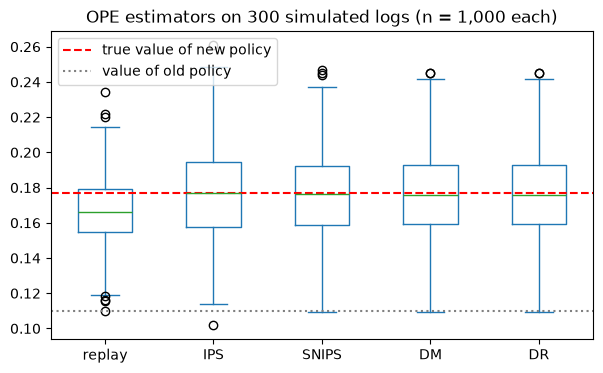

,mean,std,bias
replay,0.1675,0.0205,-0.0092
IPS,0.1774,0.0281,0.0007
SNIPS,0.1768,0.0259,0.0002
DM,0.1767,0.0259,0.0001
DR,0.1767,0.0259,0.0001


In [5]:
# bias and variance across 300 independent log samples
sims = pd.DataFrame([ope(make_logs(1000, seed=s)) for s in range(300)])
ax = sims.plot(kind="box", figsize=(7, 4))
ax.axhline(V_true_new, color="red", ls="--", label="true value of new policy")
ax.axhline(V_true_old, color="grey", ls=":", label="value of old policy")
ax.legend(); ax.set_title("OPE estimators on 300 simulated logs (n = 1,000 each)"); plt.show()
table = sims.agg(["mean", "std"]).T
table["bias"] = table["mean"] - V_true_new
table.round(4)

#### Explanation
- **Replay** is biased here (look at the `bias` column), because the old policy wasn't uniform random. It over-represents Property, where the old policy already chose the new policy's action 60% of the time. It needs uniform logs, so log some uniform exploration if you can.
- **IPS** is unbiased (bias ≈ 0) but has the widest spread (`std`).
- **DM** is unbiased here only because the reward model is the exact cell average and every cell was explored. With a wrong reward model, or a cell the old policy never tried, it would be confidently wrong.
- **DR** stays unbiased and, in real problems, is the usual default, because it survives either the propensities or the reward model being wrong.
- **None of this works without logged propensities.** That's why, from day one of any decisioning system, you log `p = π(a|x)`. That's a production-engineering habit, so it's a strong point for you to make.

---
## 6.3 Shadow Deployment

### Theory
The model receives **real live traffic**, its outputs are **logged but not used**, and humans decide as usual. Zero business risk. Measure:
1. **Engineering health:** latency (p50/p95/p99), error rate, missing or invalid inputs, data mismatches between training and serving (**training-serving skew**).
2. **Agreement with humans**, overall and **by segment**, and especially on borderline cases.
3. **Disagreement review:** sample cases where the model and the underwriter differ and have a senior underwriter adjudicate. This produces labels (DAgger-style, Notebook 03).

### Cohen's kappa: agreement beyond chance
$$\boxed{\kappa = \frac{p_o - p_e}{1 - p_e}}$$
$p_o$ = observed agreement; $p_e$ = the agreement expected by chance from each rater's base rates.

### Solved Example 6.2
**Q.** 100 submissions in shadow mode:

| | Human: Quote | Human: Decline |
|---|---|---|
| **Model: Quote** | 50 | 10 |
| **Model: Decline** | 20 | 20 |

Find the agreement and κ.

**Solution.**
$p_o = (50 + 20)/100 = 0.70$
Model quotes 60%, human quotes 70%. Model declines 40%, human declines 30%.
$p_e = 0.6 \times 0.7 + 0.4 \times 0.3 = 0.42 + 0.12 = 0.54$
$\kappa = (0.70 - 0.54)/(1 - 0.54) = 0.16 / 0.46 = $ **0.348**

**Ans.** 70% agreement sounds good, but κ = 0.35 is only "fair" agreement. Most of it comes from both sides quoting a lot.

In [6]:
human = ["Q"] * 50 + ["D"] * 10 + ["Q"] * 20 + ["D"] * 20
model = ["Q"] * 50 + ["Q"] * 10 + ["D"] * 20 + ["D"] * 20
print("agreement =", np.mean(np.array(human) == np.array(model)))
print("kappa     =", round(cohen_kappa_score(human, model), 3))

agreement = 0.7
kappa     = 0.348


#### Program 6.2: a shadow-mode report

In [7]:
rng = np.random.default_rng(5)
n = 3000
shadow = pd.DataFrame({
    "lob": rng.choice(["Property", "Marine", "Cyber"], n, p=[0.5, 0.3, 0.2]),
    "latency_ms": rng.lognormal(np.log(120), 0.4, n),
})
p_quote = shadow["lob"].map({"Property": 0.7, "Marine": 0.6, "Cyber": 0.4})
shadow["human"] = np.where(rng.random(n) < p_quote, "Quote", "Decline")
agree_p = shadow["lob"].map({"Property": 0.88, "Marine": 0.85, "Cyber": 0.62})   # model is weak on Cyber
flip = rng.random(n) > agree_p
shadow["model"] = np.where(flip, np.where(shadow["human"] == "Quote", "Decline", "Quote"), shadow["human"])

report = shadow.groupby("lob").apply(lambda g: pd.Series({
    "n": len(g),
    "agreement": (g.human == g.model).mean(),
    "kappa": cohen_kappa_score(g.human, g.model),
    "p95 latency ms": g.latency_ms.quantile(0.95),
}), include_groups=False).round(3)
report

,n,agreement,kappa,p95 latency ms
lob,,,,
Cyber,591.0,0.636,0.272,218.945
Marine,888.0,0.833,0.658,246.337
Property,1521.0,0.891,0.753,238.272


**Reading it:** overall agreement looks fine, but **Cyber** is much weaker. The action is to keep Cyber in shadow (or human-only) and promote Property first. *Segment-level shadow analysis is what turns "the model works" into a rollout plan.*

---
## 6.4 A/B Testing

### Design checklist (say these in order)
1. **Unit of randomisation:** submission, broker or underwriter? If one underwriter sees both arms, they may learn from the model and carry it into control cases (**interference / contamination**), so randomise **by underwriter or team** (cluster randomisation).
2. **Primary metric**, pre-registered: e.g. bind rate or time-to-quote.
3. **Guardrail metrics:** must not get worse: loss ratio (a delayed label!), referral rate, complaint rate, latency.
4. **Sample size / power** computed *before* starting.
5. **Run time:** fixed in advance. **No peeking** and stopping early when p < 0.05.

### Sample size for two proportions
$$\boxed{n_{\text{per arm}} = \frac{(z_{1-\alpha/2} + z_{1-\beta})^2\,[p_1(1-p_1) + p_2(1-p_2)]}{(p_1 - p_2)^2}}$$

### Solved Example 6.3
**Q.** Bind rate is 30%. We want to detect a lift to 33% with α = 0.05 (two-sided) and power 80%. How many submissions per arm?

**Solution.** $z_{0.975} = 1.96$ and $z_{0.80} = 0.8416$, so the sum is 2.8016 and its square is 7.849.
Variance term = 0.30(0.70) + 0.33(0.67) = 0.2100 + 0.2211 = 0.4311.
Difference² = 0.03² = 0.0009.
$n = 7.849 \times 0.4311 / 0.0009 = $ **3,760 per arm**

**Ans.** About 7,500 submissions in total. If Aventum sees, say, 500 relevant submissions a week, that's about 15 weeks. **Small lifts need big samples**, which is why you agree the minimum detectable effect with the business first.

In [8]:
def n_per_arm(p1, p2, alpha=0.05, power=0.8):
    z_a = stats.norm.ppf(1 - alpha / 2); z_b = stats.norm.ppf(power)
    return (z_a + z_b) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p1 - p2) ** 2

print("formula     :", round(n_per_arm(0.30, 0.33)))
h = proportion_effectsize(0.33, 0.30)
print("statsmodels :", round(NormalIndPower().solve_power(effect_size=h, alpha=0.05, power=0.8)),
      "(uses the arcsine effect size h, so slightly different)")
for lift in [0.01, 0.02, 0.03, 0.05]:
    print(f"  lift {lift:.0%}: {round(n_per_arm(0.30, 0.30 + lift)):>7,} per arm")

formula     : 3760
statsmodels : 3762 (uses the arcsine effect size h, so slightly different)
  lift 1%:  33,271 per arm
  lift 2%:   8,390 per arm
  lift 3%:   3,760 per arm
  lift 5%:   1,374 per arm


#### Program 6.3: run and analyse one A/B test

In [9]:
rng = np.random.default_rng(21)
n = 3760
control = rng.random(n) < 0.30
treat   = rng.random(n) < 0.33
z, p = proportions_ztest([treat.sum(), control.sum()], [n, n])
diff = treat.mean() - control.mean()
se = np.sqrt(treat.mean() * (1 - treat.mean()) / n + control.mean() * (1 - control.mean()) / n)
print(f"bind rate control {control.mean():.3f} | treatment {treat.mean():.3f}")
print(f"lift = {diff:+.3f}, 95% CI [{diff - 1.96 * se:+.3f}, {diff + 1.96 * se:+.3f}], z = {z:.2f}, p = {p:.4f}")

bind rate control 0.294 | treatment 0.324
lift = +0.030, 95% CI [+0.009, +0.050], z = 2.77, p = 0.0056


#### Program 6.4: why peeking is forbidden (A/A test)
Both arms are **identical** (no real effect). If you check the p-value after every 200 submissions and stop as soon as p < 0.05, how often do you falsely declare a winner?

In [10]:
rng = np.random.default_rng(0)
def peeking_false_positive(n_max=4000, step=200, sims=500):
    hits = 0
    for _ in range(sims):
        a = rng.random(n_max) < 0.3; b = rng.random(n_max) < 0.3
        for k in range(step, n_max + 1, step):
            _, p = proportions_ztest([a[:k].sum(), b[:k].sum()], [k, k])
            if p < 0.05:
                hits += 1; break
    return hits / sims

print("False-positive rate with one look at the end : about 0.05 (by design)")
print("False-positive rate peeking every 200 units  :", peeking_false_positive())

False-positive rate with one look at the end : about 0.05 (by design)


False-positive rate peeking every 200 units  : 0.268


#### Explanation
Every look is another chance for noise to cross p < 0.05, so with 20 looks the false-positive rate is several times 5%. **Fixes:** fix the sample size in advance, or use a **sequential test** (alpha spending, e.g. O'Brien–Fleming) or a Bayesian approach designed for continuous monitoring.

---
## 6.5 Canary Releases and Rollback

**Canary:** route a small share (1 to 5%) of live traffic to the new model, compare health metrics against the current model in real time, and **roll back automatically** if a guardrail trips. It's about *safety*, not statistical proof. (The A/B test is the proof.)

In [11]:
def canary_decision(new_err, old_err, new_p95, old_p95, max_err_ratio=1.2, max_latency_ratio=1.3):
    reasons = []
    if new_err > old_err * max_err_ratio:  reasons.append("error rate")
    if new_p95 > old_p95 * max_latency_ratio: reasons.append("p95 latency")
    return ("ROLLBACK: " + ", ".join(reasons)) if reasons else "PROMOTE to next stage (e.g. 25%)"

print(canary_decision(new_err=0.004, old_err=0.005, new_p95=180, old_p95=170))
print(canary_decision(new_err=0.011, old_err=0.005, new_p95=400, old_p95=170))

PROMOTE to next stage (e.g. 25%)
ROLLBACK: error rate, p95 latency


Your HDFC experience maps here: a one-click Jenkins deploy to dev/prod, separate containers per service, and the security/VAPT gate. Say that's the foundation, and that canary plus automatic rollback is the next step you'd add. **Don't claim you ran canaries.**

---
## Exercise 6.1
1. In Solved Example 6.1, add a 5th row: Cyber, revised terms, p = 0.25, r = 0. Recompute IPS and SNIPS.
2. Why is the replay method biased in Program 6.1 but unbiased for logs from a uniform-random policy?
3. Shadow mode: the model agrees 95% of the time with underwriters. Give two reasons to stay cautious.
4. Using the formula, how many per arm to detect 30% → 35%?
5. You want to A/B test an underwriter-assist tool. Why randomise by underwriter rather than by submission? What does it cost you?
6. Order the ladder: A/B test, shadow, offline replay, full rollout, canary.

<details><summary><b>Answers</b></summary>

1. Weights: 2, 0, 4, 0, 4. Rewards 1, 0, 1, 1, 0. IPS = (2 + 4)/5 = **1.2**. SNIPS = 6/(2 + 4 + 4) = **0.6**.
2. Replay keeps rows where the logged action matches the new policy. If logging was uniform, those rows are a random sample of contexts, whatever the action. With a non-uniform policy, the matched rows over-represent contexts where the old policy happened to like the same action.
3. (a) Agreement ≠ correctness: the humans might be wrong. (b) Most cases are easy, so check the borderline and minority segments. (c) If underwriters can see the model's output, they may anchor on it. (d) κ may be much lower than 95% suggests if base rates are skewed.
4. Variance = 0.21 + 0.2275 = 0.4375; diff² = 0.0025; n = 7.849 × 0.4375 / 0.0025 ≈ **1,374 per arm**.
5. Contamination: an underwriter who sees the tool's suggestions on treatment cases changes how they handle control cases. Cluster randomisation fixes that but needs a larger sample (the effective sample size shrinks with within-cluster correlation, the design effect).
6. Offline replay → shadow → canary → A/B test → full rollout.
</details>

## Viva / Interview Questions
**Q. How do you take a model from notebook to production?** (STRATEGY §6.1, steps 5 to 7)
Package it behind a FastAPI service in Docker, triggered by the business event, returning reasons along with the score. Version data, model and code together. Then the ladder: offline replay over historical decisions, shadow mode on live traffic with segment-level agreement and latency, a canary with automatic rollback, an A/B test with a pre-registered metric and guardrails, and full rollout with drift and delayed-label monitoring. A human override always stays, with an audit log.

**Q. Your model looks great offline but underwriters ignore it.**
Look at the shadow data first: where do they disagree, and who's right on adjudication? Then explainability (reason codes) and workflow fit: is the score shown at the moment of decision? Then talk to the users. At HDFC the apps improved most after real users got them and we iterated on their feedback.

## Formula Sheet
| Concept | Formula |
|---|---|
| IPS | $\frac1n \sum \frac{\pi_e(a \mid x)}{p} r$ |
| SNIPS | $\sum w r / \sum w$ |
| DR | $\frac1n \sum [\hat r(x, \pi_e) + w(r - \hat r(x,a))]$ |
| Cohen's κ | $(p_o - p_e)/(1 - p_e)$ |
| Sample size | $(z_{\alpha/2} + z_\beta)^2 [p_1 q_1 + p_2 q_2] / (p_1 - p_2)^2$ |

## How to say it on Friday
> "At HDFC, quality came from user feedback and Compliance review rather than controlled experiments, so that's an area I'd grow into. I've worked through the mechanics: off-policy estimators on logged data, shadow agreement with kappa, power calculations. If I joined, the first thing I'd build is shadow-mode infrastructure and an offline replay harness, so every behavioural model can be validated safely before it touches a decision."